<p align='center'><img src='../assets/logo_team.png' width='140'></p>

<h1 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice V · Modèle de coût et prime pure DDE</h1>

Le coût moyen d'un sinistre est modélisé par un **GLM Gamma** à lien log, sur les seules lignes sinistrées, avec le
nombre de sinistres en poids (`var_weights`) : la variance du coût moyen d'une ligne à $n$ sinistres est divisée par
$n$. La prime pure vaut ensuite **fréquence × exposition × coût moyen**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src import theme as T, graphiques as GR
from src.data import *
from src.indicateurs import *
from src import modeles as M
print("Rendu :", T.configurer_notebook())
pd.options.display.float_format = "{:,.4f}".format

Rendu : plotly_mimetype+notebook_connected+png


In [2]:
bd = charger_base()                                  # base complète (1 112 095 lignes)
bda, bdt, samp = decouper(bd, seed=2016)             # np.random.seed(2016) ; np.random.choice(len(bd), 300000)
print(f"Base : {bd.shape} · apprentissage : {len(bda):,} · test : {len(bdt):,}")

bdc = base_cout(bda, 'DDE')
print(f'Lignes sinistrées (apprentissage) : {len(bdc):,}')

Base : (1112095, 24) · apprentissage : 300,000 · test : 812,095
Lignes sinistrées (apprentissage) : 5,258


<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">1. Modèle GLM Gamma sur le coût moyen</h3>

In [3]:
c0 = M.glm_cout(bdc, [])
print(f"exp(intercept) = {np.exp(c0.params['Intercept']):,.2f} € · CM observé = {bdc['Cout_DDE'].sum() / bdc['Sini_DDE'].sum():,.2f} €")
c_inv = M.glm_cout(bdc, [], lien="inverse")
print(f"Lien inverse : 1 / intercept = {1 / c_inv.params['Intercept']:,.2f} €")

exp(intercept) = 1,327.37 € · CM observé = 1,327.37 €
Lien inverse : 1 / intercept = 1,327.37 €


/usr/local/lib/python3.13/site-packages/statsmodels/base/model.py:243: DomainWarning: The InversePower link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)


,Variable,Statistique,p-value,ddl
0,Local,63.8,4.57e-13,4
1,Nbpieces,50.8,5.45e-11,3
2,Qualite,17.3,3.14e-05,1
3,Usage,14.2,8.38e-04,2
4,Kassu,12.0,9.93e-02,7
5,Age2,9.1,5.84e-02,4
6,Zonier_DDE,3.1,3.72e-01,3
7,Couverture,2.8,2.52e-01,2
8,Nbpers,2.0,7.41e-01,4
9,Direct,1.9,1.71e-01,1


Variables retenues pour le coût : ['Nbpieces', 'Qualite', 'Usage', 'Local']


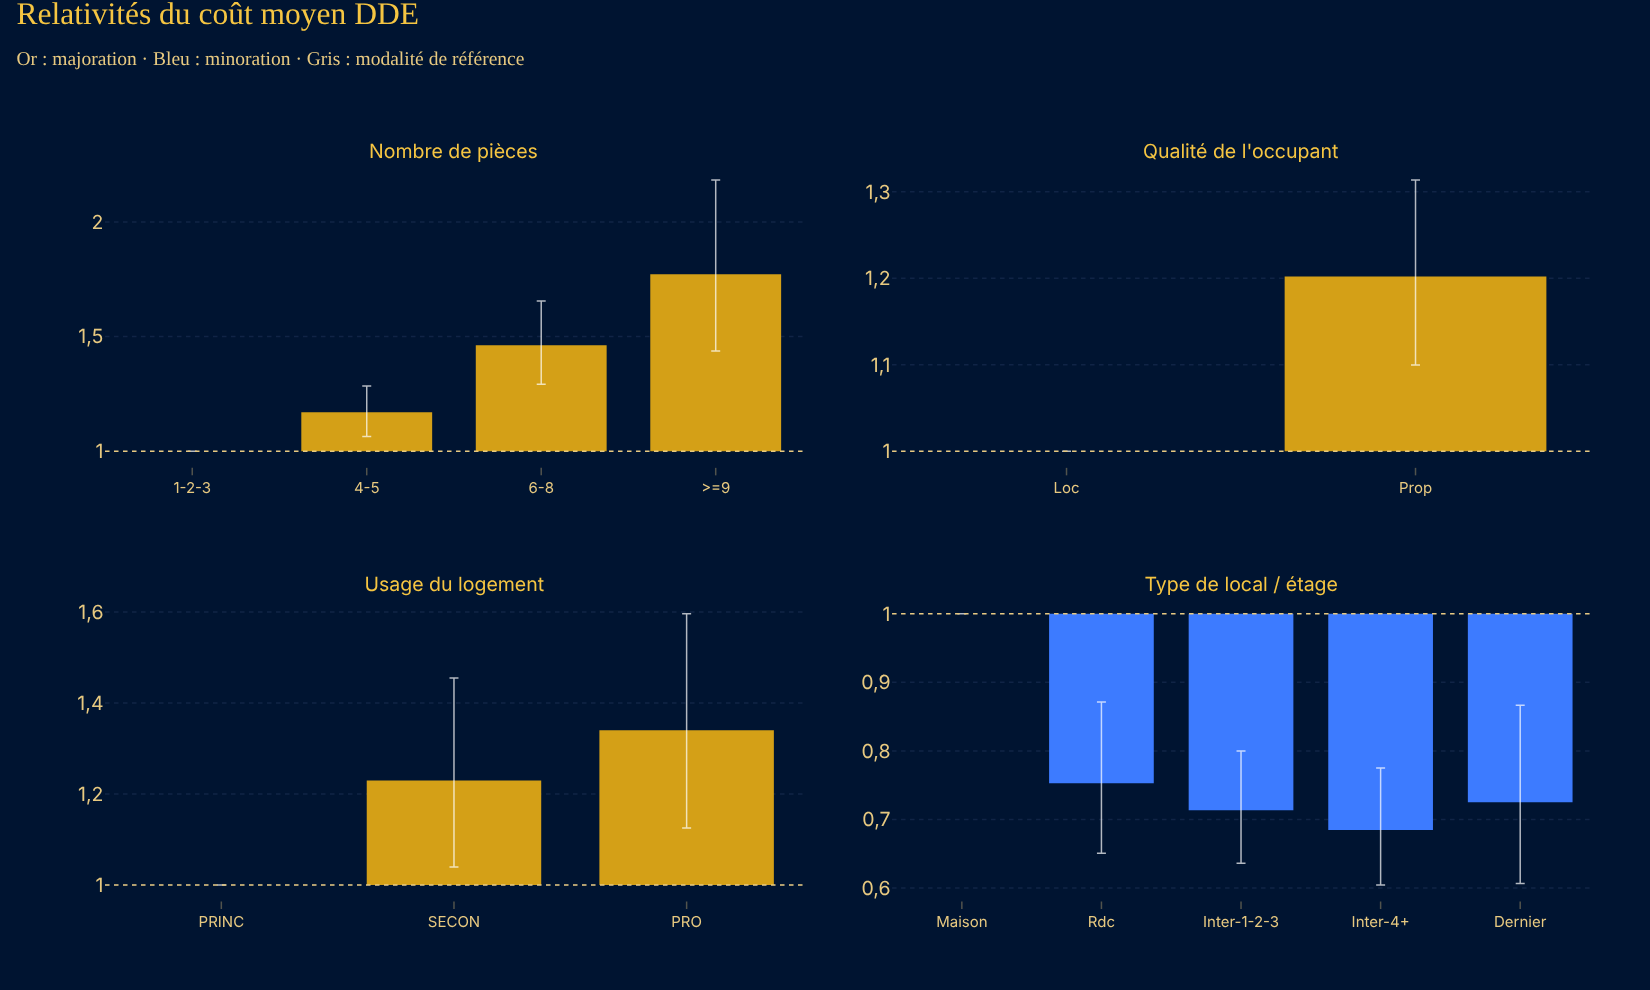

In [4]:
c_complet = M.glm_cout(bdc, VAR_TARIF_DDE)
wald_c = M.importance_wald(c_complet)
display(wald_c.style.format({"Statistique": "{:.1f}", "p-value": "{:.2e}"}))
var_cout = [v for v in VAR_TARIF_DDE if v in set(wald_c.loc[wald_c["p-value"] < 0.05, "Variable"])]
fit_c = M.glm_cout(bdc, var_cout)
print("Variables retenues pour le coût :", var_cout)
GR.relativites_grille(M.relativites(fit_c), var_cout, "Relativités du coût moyen DDE", cols=2).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Le coût moyen est bien moins segmentant que la fréquence : seules quelques variables liées à la taille et au type de logement (Nbpieces, Local, Qualite, Usage) sont significatives. Les grands logements, les maisons et les propriétaires (qui déclarent aussi le bâti) ont des sinistres plus coûteux. Le lien log donne des relativités multiplicatives, combinables avec la fréquence ; le lien inverse canonique du cours ne l'est pas.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">2. Primes pures</h3>

In [5]:
var_freq = pd.read_json(Path.cwd().parent / "models" / "resume.json", typ="series")["var_freq_dde"]
fit_f = M.glm_freq(bda, var_freq)
print("Variables du modèle de fréquence (backward + Kassu regroupé) :", var_freq)
pp_a, pp_t = M.prime_pure(fit_f, fit_c, bda), M.prime_pure(fit_f, fit_c, bdt)
for nom, df, pp in [("Apprentissage", bda, pp_a), ("Test", bdt, pp_t)]:
    print(f"{nom:13s} charge observée {df['Cout_DDE'].sum():>14,.0f} € · prédite {pp.sum():>14,.0f} € "
          f"· écart {pp.sum() / df['Cout_DDE'].sum() - 1:+.2%}")
print(f"Prime pure annuelle moyenne (test) : {pp_t.sum() / bdt['Expo'].sum():.2f} €")

Variables du modèle de fréquence (backward + Kassu regroupé) : ['Couverture', 'Nbpieces', 'Nbpers', 'Qualite', 'Kassu_reg', 'Age2', 'Usage', 'Local', 'DMG', 'Zonier_DDE', 'Ante_DDE']


Apprentissage charge observée      7,344,340 € · prédite      7,337,344 € · écart -0.10%
Test          charge observée     19,852,914 € · prédite     19,855,798 € · écart +0.01%
Prime pure annuelle moyenne (test) : 23.19 €


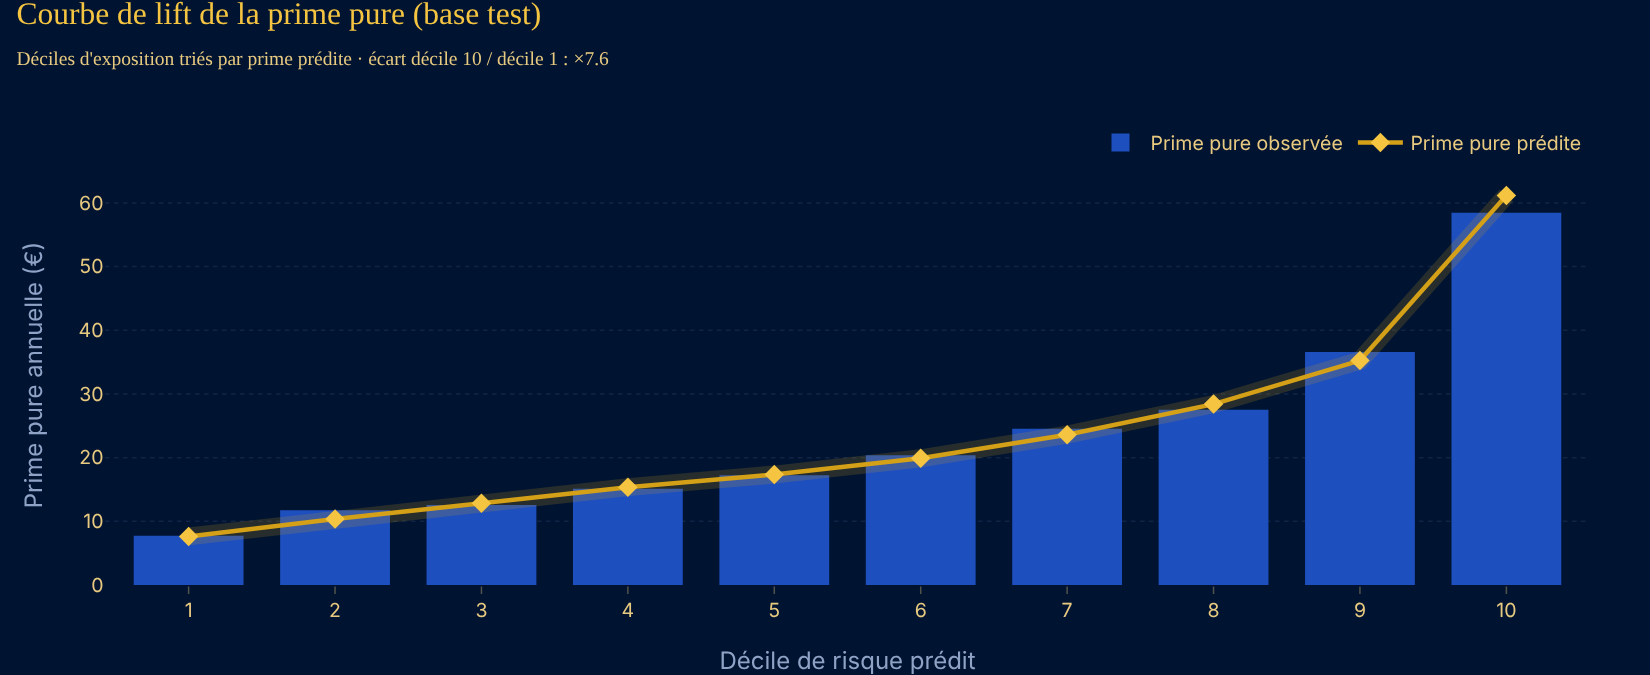

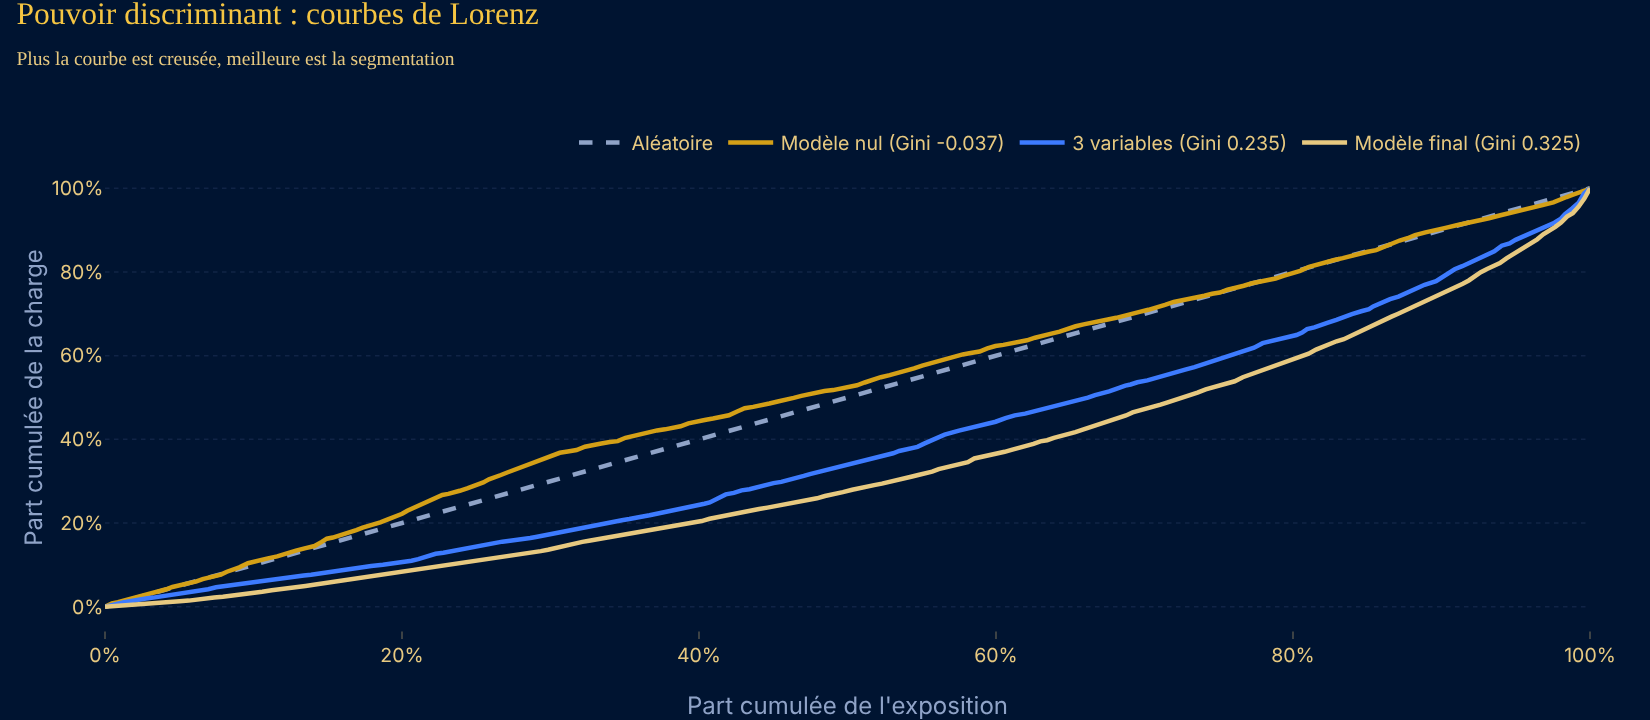

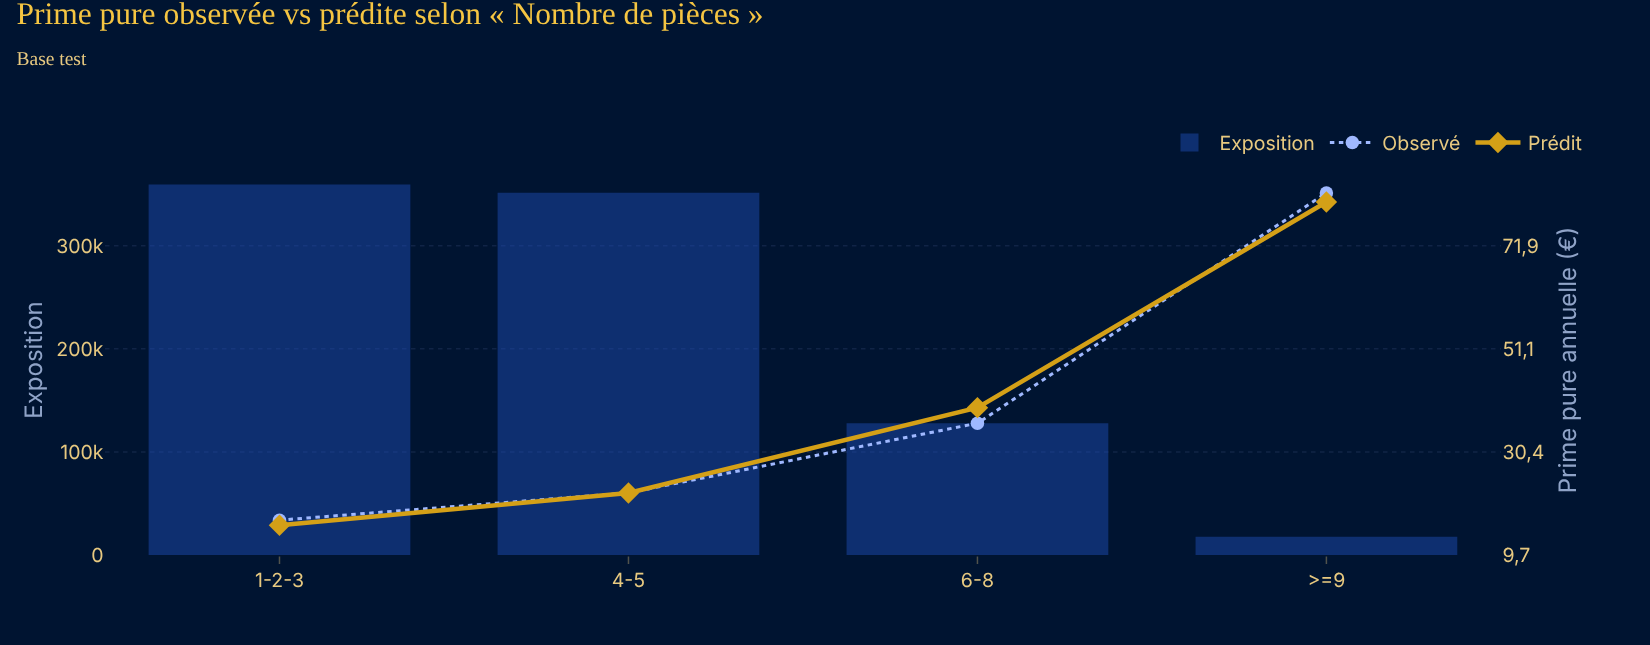

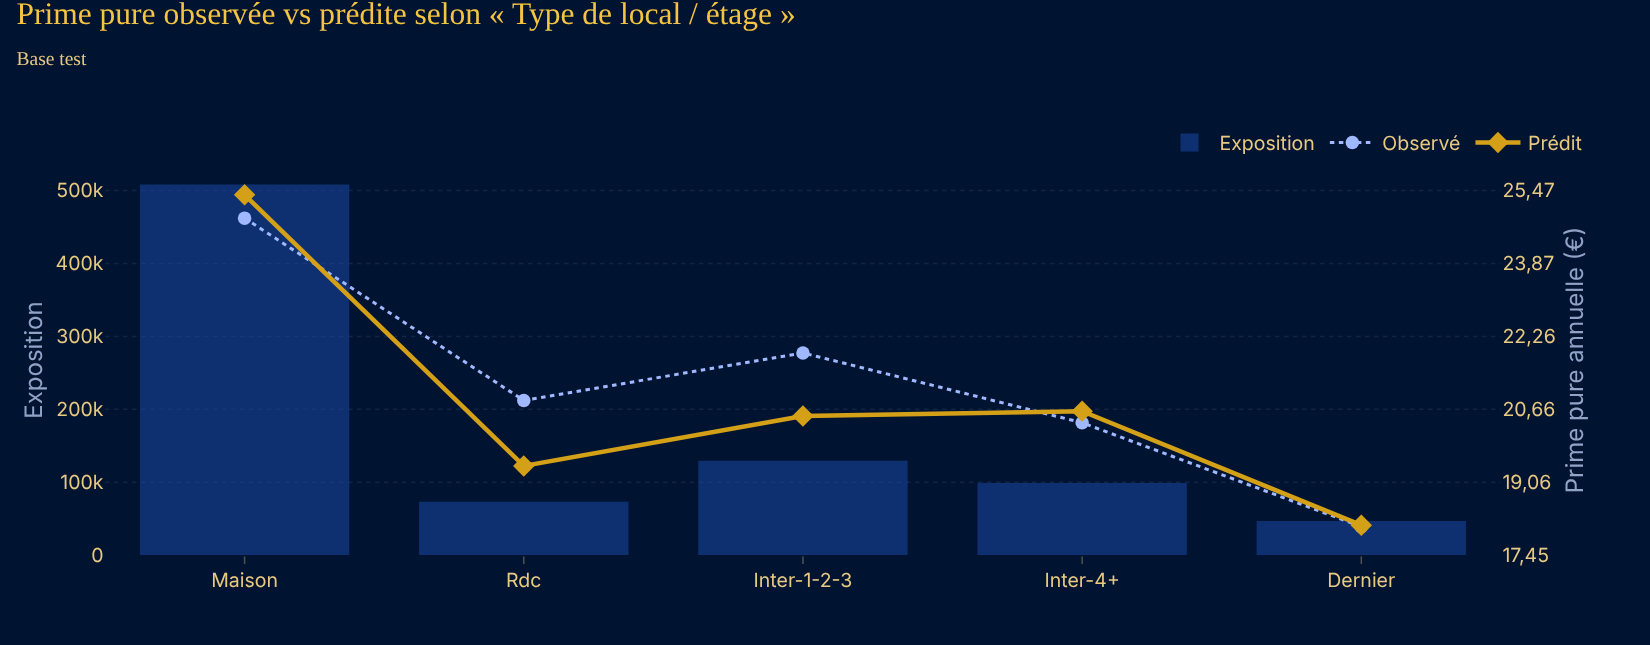

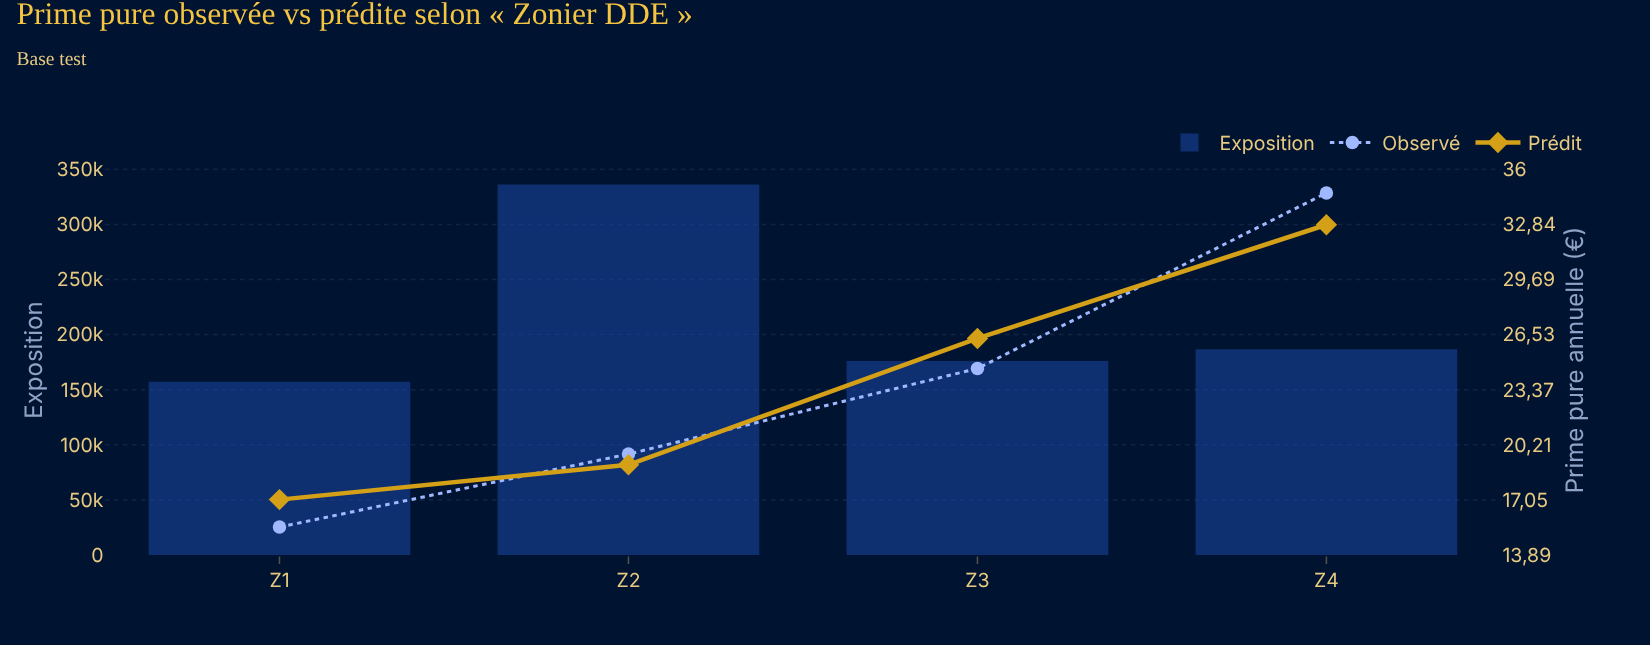

In [6]:
GR.lift(M.table_lift(pp_t, bdt["Cout_DDE"], bdt["Expo"])).show()
m0 = M.glm_freq(bda, []); c0 = M.glm_cout(bdc, [])
f3 = M.glm_freq(bda, ["Nbpieces", "Nbpers", "Qualite"]); c3 = M.glm_cout(bdc, ["Nbpieces", "Nbpers", "Qualite"])
preds = {"Modèle nul": M.prime_pure(m0, c0, bdt), "3 variables": M.prime_pure(f3, c3, bdt), "Modèle final": pp_t}
GR.lorenz({k: M.courbe_lorenz(v, bdt["Cout_DDE"], bdt["Expo"]) for k, v in preds.items()},
          {k: M.gini(v, bdt["Cout_DDE"], bdt["Expo"]) for k, v in preds.items()}).show()
for v in ["Nbpieces", "Local", "Zonier_DDE"]:
    GR.observe_predit(M.observe_vs_predit(bdt, pp_t, v), v).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> La charge prédite est quasi égale à la charge observée sur l'apprentissage (−0,1 % : la Gamma à lien log n'est pas le lien canonique, l'équilibre n'est donc pas exact) et à +0,01 % sur la base test : le tarif est bien calibré en moyenne. La courbe de lift est croissante et suivie par la prédiction, et l'indice de Gini du modèle final dépasse nettement celui d'un modèle à 3 variables : le tarif hiérarchise correctement les risques, ce qui sera décisif en marché concurrentiel (exercice VI).</div>